In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ModuleNotFoundError: No module named 'yfinance'

: 

In [ ]:
import yfinance as yf

stock_name = "LAURUSLABS.NS"

df = yf.download(stock_name, start="2020-01-01", end="2026-04-17")

df.tail()

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,LAURUSLABS.NS,LAURUSLABS.NS,LAURUSLABS.NS,LAURUSLABS.NS,LAURUSLABS.NS
Date,,,,,
2026-04-09,1083.699951,1090.900024,1074.050049,1081.000000,974649
2026-04-10,1098.349976,1109.000000,1079.599976,1091.099976,1769594
2026-04-13,1087.800049,1092.800049,1072.550049,1080.599976,1313173
2026-04-15,1117.599976,1124.000000,1093.750000,1122.000000,1723052
2026-04-16,1128.349976,1135.750000,1112.800049,1127.000000,1250244


In [ ]:
close_prices = pd.DataFrame()

for stock in stocks:
    close_prices[stock] = data[stock]["Close"]

In [ ]:
close_prices.fillna(method='ffill', inplace=True)
close_prices.dropna(inplace=True)

C:\Users\Shreyansh\AppData\Local\Temp\ipykernel_17512\1321584256.py:1: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  close_prices.fillna(method='ffill', inplace=True)


In [ ]:
from sklearn.preprocessing import MinMaxScaler

stock_index = stocks.index(stock_name)

stock_name = stocks[stock_index]

stock_data = data[stock_name][["Open", "High", "Low", "Close", "Volume"]].values


In [ ]:
split = int(0.8 * len(stock_data))

train_data = stock_data[:split]
test_data = stock_data[split:]

In [ ]:
scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train_data)

In [ ]:
test_scaled = scaler.transform(test_data)
scaled_data = np.vstack((train_scaled, test_scaled))

In [ ]:
X = []
y = []

for i in range(60, len(scaled_data)):
    X.append(scaled_data[i-60:i])
    y.append([scaled_data[i][0], scaled_data[i][3]])

X = np.array(X)
y = np.array(y)

In [ ]:
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, GRU, Dense, Dropout

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True
)

In [ ]:
lstm_model = Sequential()

lstm_model.add(LSTM(128, return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])))
lstm_model.add(Dropout(0.05))

lstm_model.add(LSTM(256, return_sequences=True))  # ✅ keep True
lstm_model.add(Dropout(0.05))

lstm_model.add(LSTM(128))  # ✅ last one (no return_sequences)
lstm_model.add(Dropout(0.05))

lstm_model.add(Dense(2))

lstm_model.compile(optimizer='adam', loss='mean_squared_error')

c:\Users\Shreyansh\anaconda3\envs\sekiro\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
print(X.shape)
print(y.shape)

(1497, 60, 5)
(1497, 2)


In [ ]:
lstm_history = lstm_model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=32,
    validation_data=(X_test, y_test),
    callbacks=[early_stop]
)

Epoch 1/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 8s 122ms/step - loss: 0.0211 - val_loss: 0.0834
Epoch 2/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 4s 90ms/step - loss: 0.0026 - val_loss: 0.0286
Epoch 3/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 3s 88ms/step - loss: 0.0023 - val_loss: 0.0138
Epoch 4/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 4s 91ms/step - loss: 0.0022 - val_loss: 0.0112
Epoch 5/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 4s 98ms/step - loss: 0.0023 - val_loss: 0.0091
Epoch 6/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 4s 92ms/step - loss: 0.0021 - val_loss: 0.0201
Epoch 7/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 4s 106ms/step - loss: 0.0020 - val_loss: 0.0388
Epoch 8/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 4s 111ms/step - loss: 0.0018 - val_loss: 0.0072
Epoch 9/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 4s 111ms/step - loss: 0.0016 - val_loss: 0.0081
Epoch 10/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 5s 139ms/step - loss: 0.0016 - val_loss: 0.0066
Epoch 11/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 5s 141ms/step - loss: 0.0017 - val_loss: 0.0072
Epoch 12/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 6s 147

In [ ]:
lstm_predictions = lstm_model.predict(X_test)

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step


In [ ]:
gru_model = Sequential()

gru_model.add(GRU(64, return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])))
gru_model.add(Dropout(0.2))

gru_model.add(GRU(64))
gru_model.add(Dropout(0.2))

gru_model.add(Dense(2))

gru_model.compile(optimizer='adam', loss='mean_squared_error')

gru_model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_2 (GRU)                     │ (None, 60, 64)         │        13,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_3 (GRU)                     │ (None, 64)             │        24,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,722 (151.26 KB)

 Trainable params: 38,722 (151.26 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
gru_history = gru_model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=32,
    validation_data=(X_test, y_test),
    # callbacks=[early_stop]
)

Epoch 1/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - loss: 0.0457 - val_loss: 0.0263
Epoch 2/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 0.0088 - val_loss: 0.0280
Epoch 3/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 0.0068 - val_loss: 0.0120
Epoch 4/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0052 - val_loss: 0.0053
Epoch 5/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0046 - val_loss: 0.0069
Epoch 6/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0044 - val_loss: 0.0039
Epoch 7/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 0.0042 - val_loss: 0.0053
Epoch 8/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0039 - val_loss: 0.0179
Epoch 9/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0039 - val_loss: 0.0034
Epoch 10/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0035 - val_loss: 0.0029
Epoch 11/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0039 - val_loss: 0.0033
Epoch 12/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step

In [ ]:
gru_predictions = gru_model.predict(X_test)

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


In [ ]:
from sklearn.metrics import mean_squared_error

lstm_rmse = np.sqrt(mean_squared_error(y_test, lstm_predictions))
gru_rmse = np.sqrt(mean_squared_error(y_test, gru_predictions))

print("LSTM RMSE:", lstm_rmse)
print("GRU RMSE:", gru_rmse)

LSTM RMSE: 0.02869708773284994
GRU RMSE: 0.022681691680830816


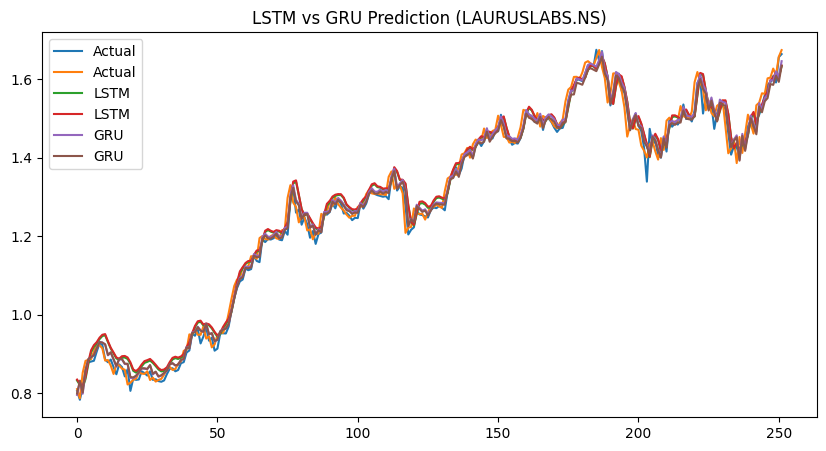

In [ ]:
plt.figure(figsize=(10,5))

plt.plot(y_test, label="Actual")
plt.plot(lstm_predictions, label="LSTM")
plt.plot(gru_predictions, label="GRU")

plt.title(f"LSTM vs GRU Prediction ({stock_name})")
plt.legend()
plt.show()

In [ ]:
# LSTM predictions
# LSTM
dummy_lstm = np.zeros((len(lstm_predictions), 5))
dummy_lstm[:, 0] = lstm_predictions[:, 0]
dummy_lstm[:, 3] = lstm_predictions[:, 1]

pred_lstm_real = scaler.inverse_transform(dummy_lstm)

open_pred_lstm = pred_lstm_real[:, 0]
close_pred_lstm = pred_lstm_real[:, 3]

# GRU predictions
dummy_gru = np.zeros((len(gru_predictions), 5))
dummy_gru[:, 0] = gru_predictions[:, 0]
dummy_gru[:, 3] = gru_predictions[:, 1]

pred_gru_real = scaler.inverse_transform(dummy_gru)

open_pred_gru = pred_gru_real[:, 0]
close_pred_gru = pred_gru_real[:, 3]


# Actual values
# Create dummy
dummy_y = np.zeros((len(y_test), 5))

# Assign correctly
dummy_y[:, 0] = y_test[:, 0]  # Open
dummy_y[:, 3] = y_test[:, 1]  # Close

# Inverse transform
y_real = scaler.inverse_transform(dummy_y)

# Extract
open_actual = y_real[:, 0]
close_actual = y_real[:, 3]

y_test_real = scaler.inverse_transform(dummy_y)[:, 3]

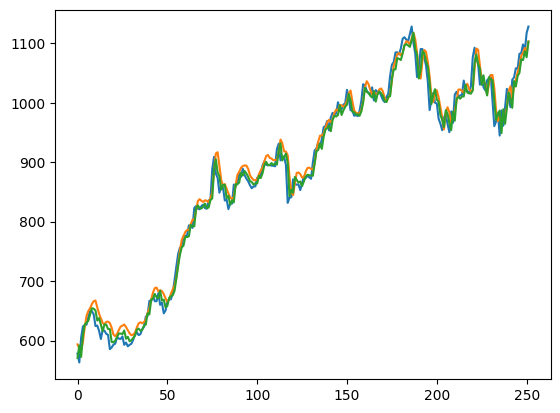

In [ ]:
plt.plot(close_actual, label="Actual Close")
plt.plot(close_pred_lstm, label="LSTM Close")
plt.plot(close_pred_gru, label="GRU Close")

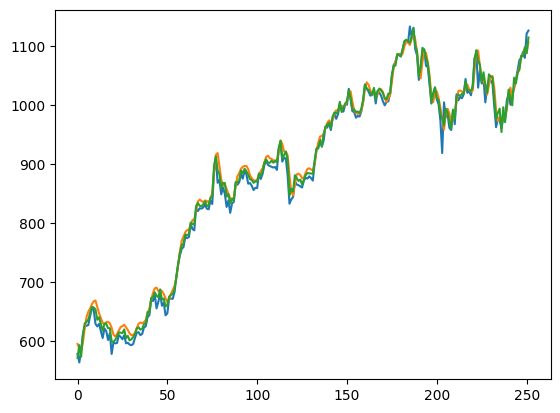

In [ ]:
plt.plot(open_actual, label="Actual Open")
plt.plot(open_pred_lstm, label="LSTM Open")
plt.plot(open_pred_gru, label="GRU Open")

In [ ]:
print("Train loss:", lstm_history.history['loss'][-1])
print("Val loss:", lstm_history.history['val_loss'][-1])

Train loss: 0.0006943769985809922
Val loss: 0.007366879377514124


In [ ]:
# Take last 60 days (already scaled OHLCV)
last_60_days = scaled_data[-60:]

# Reshape for model
last_60_days = last_60_days.reshape(1, 60, 5)

In [ ]:
# LSTM prediction
next_pred_lstm = lstm_model.predict(last_60_days)

# GRU prediction
next_pred_gru = gru_model.predict(last_60_days)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


In [ ]:
dummy_lstm = np.zeros((1, 5))

dummy_lstm[0, 0] = next_pred_lstm[0, 0]  # Open
dummy_lstm[0, 3] = next_pred_lstm[0, 1]  # Close

next_lstm_real = scaler.inverse_transform(dummy_lstm)

lstm_open = next_lstm_real[0, 0]
lstm_close = next_lstm_real[0, 3]

In [ ]:
dummy_gru = np.zeros((1, 5))

dummy_gru[0, 0] = next_pred_gru[0, 0]
dummy_gru[0, 3] = next_pred_gru[0, 1]

next_gru_real = scaler.inverse_transform(dummy_gru)

gru_open = next_gru_real[0, 0]
gru_close = next_gru_real[0, 3]

In [ ]:
print("📊 NEXT DAY PREDICTION")

print(f"LSTM → Open: ₹{lstm_open:.2f}, Close: ₹{lstm_close:.2f}")
print(f"GRU  → Open: ₹{gru_open:.2f}, Close: ₹{gru_close:.2f}")

📊 NEXT DAY PREDICTION
LSTM → Open: ₹1123.07, Close: ₹1119.19
GRU  → Open: ₹1125.41, Close: ₹1112.52


In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

def evaluate_model(y_true, y_pred, name="Model"):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae  = mean_absolute_error(y_true, y_pred)
    r2   = r2_score(y_true, y_pred)

    print(f"\n{name} Performance:")
    print(f"RMSE: {rmse:.4f}")
    print(f"MAE : {mae:.4f}")
    print(f"R²  : {r2:.4f}")

    return rmse, mae, r2

# ✅ USE CORRECT VARIABLES
lstm_metrics = evaluate_model(y_test, lstm_predictions, "LSTM")
gru_metrics  = evaluate_model(y_test, gru_predictions, "GRU")


LSTM Performance:
RMSE: 0.0287
MAE : 0.0226
R²  : 0.9869

GRU Performance:
RMSE: 0.0227
MAE : 0.0164
R²  : 0.9918


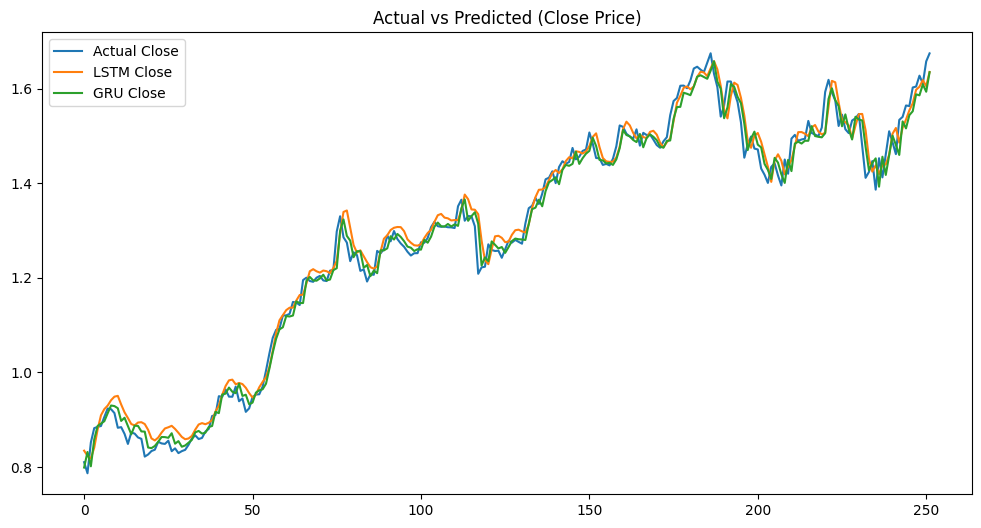

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

plt.plot(y_test[:,1], label="Actual Close")
plt.plot(lstm_predictions[:,1], label="LSTM Close")
plt.plot(gru_predictions[:,1], label="GRU Close")

plt.title("Actual vs Predicted (Close Price)")
plt.legend()
plt.show()

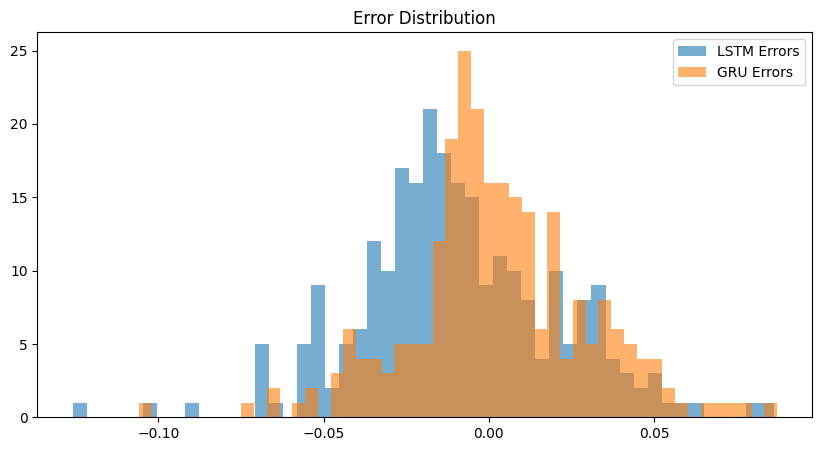

In [ ]:
lstm_residuals = y_test[:,1] - lstm_predictions[:,1]
gru_residuals  = y_test[:,1] - gru_predictions[:,1]

plt.figure(figsize=(10,5))

plt.hist(lstm_residuals, bins=50, alpha=0.6, label="LSTM Errors")
plt.hist(gru_residuals, bins=50, alpha=0.6, label="GRU Errors")

plt.title("Error Distribution")
plt.legend()
plt.show()

In [ ]:
def direction_accuracy(y_true, y_pred):
    actual_dir = np.sign(y_true[:,1] - y_true[:,0])
    pred_dir   = np.sign(y_pred[:,1] - y_pred[:,0])

    return np.mean(actual_dir == pred_dir)

print("LSTM Direction Accuracy:", direction_accuracy(y_test, lstm_predictions))
print("GRU Direction Accuracy :", direction_accuracy(y_test, gru_predictions))

LSTM Direction Accuracy: 0.6746031746031746
GRU Direction Accuracy : 0.373015873015873
